In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [13]:
df = pd.read_csv(
    "waterquality.csv",
    sep=";",
    decimal="."
)

In [14]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             900 non-null    int64  
 1   river_section  900 non-null    object 
 2   saison         900 non-null    object 
 3   nitrate_mgL    900 non-null    float64
 4   oxygen_mgL     900 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 35.3+ KB
None


In [15]:
print(df.describe())

               ID  nitrate_mgL  oxygen_mgL
count  900.000000   900.000000  900.000000
mean   450.500000     8.811672    8.971169
std    259.951919     2.873274    1.425223
min      1.000000     1.510000    4.608000
25%    225.750000     6.762250    8.057500
50%    450.500000     8.887000    9.263500
75%    675.250000    10.926750    9.979000
max    900.000000    16.444000   12.167000


In [16]:
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

Dataset shape: (900, 5)

Column names: ['ID', 'river_section', 'saison', 'nitrate_mgL', 'oxygen_mgL']


In [17]:
display(df.head(10))

,ID,river_section,saison,nitrate_mgL,oxygen_mgL
0,1,A1_headwaters,spring,5.540,10.711
1,2,A1_headwaters,spring,3.328,9.937
2,3,A1_headwaters,spring,5.742,10.499
3,4,A1_headwaters,spring,7.822,10.405
4,5,A1_headwaters,spring,8.843,10.245
5,6,A1_headwaters,spring,5.354,8.834
6,7,A1_headwaters,spring,5.614,9.596
7,8,A1_headwaters,spring,3.355,10.167
8,9,A1_headwaters,spring,6.690,8.906
9,10,A1_headwaters,spring,5.040,9.234


In [18]:
print("\nData types:")
print(df.dtypes)


Data types:
ID                 int64
river_section     object
saison            object
nitrate_mgL      float64
oxygen_mgL       float64
dtype: object


In [19]:
measurements = ["nitrate_mgL", "oxygen_mgL"]

In [20]:
# 1. Missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Duplicate observations
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())

# 3. Negative concentrations
print("\nNegative values:")
print((df[measurements] < 0).sum())

# 4. Non-finite values
print("\nNon-finite measurements:")
print((~np.isfinite(df[measurements])).sum())

# 5. Minimum and maximum concentrations
print("\nMeasurement ranges (mg/L):")
display(df[measurements].agg(["min", "max"]))

Missing values:
ID               0
river_section    0
saison           0
nitrate_mgL      0
oxygen_mgL       0
dtype: int64

Duplicate rows: 0
Duplicate IDs: 0

Negative values:
nitrate_mgL    0
oxygen_mgL     0
dtype: int64

Non-finite measurements:
nitrate_mgL    0
oxygen_mgL     0
dtype: int64

Measurement ranges (mg/L):


,nitrate_mgL,oxygen_mgL
min,1.510,4.608
max,16.444,12.167


In [21]:
# Define the expected ordering
season_order = ["spring", "summer", "autumn", "winter"]

section_order = [
    "A1_headwaters",
    "A2_upper_course",
    "A3_middle_course",
    "A4_lower_course",
    "A5_mouth"
]

In [22]:
# Check category labels
assert set(df["saison"].unique()) == set(season_order)
assert set(df["river_section"].unique()) == set(section_order)

In [23]:
# Create a frequency table
group_counts = pd.crosstab(
    df["river_section"],
    df["saison"]
).reindex(
    index=section_order,
    columns=season_order
)

display(group_counts)

saison,spring,summer,autumn,winter
river_section,,,,
A1_headwaters,45,45,45,45
A2_upper_course,45,45,45,45
A3_middle_course,45,45,45,45
A4_lower_course,45,45,45,45
A5_mouth,45,45,45,45


In [24]:
# Validate the expected study structure
assert len(df) == 900
assert (group_counts == 45).all().all()

print("Dataset structure verified successfully.")

Dataset structure verified successfully.


In [26]:

# Response variables
measurements = ["oxygen_mgL", "nitrate_mgL"]

def describe_concentrations(frame):
    # Generate descriptive statistics
    result = frame[measurements].describe().T

    # Calculate interquartile range
    result["IQR"] = result["75%"] - result["25%"]

    # Improve column names
    result = result.rename(columns={
        "count": "N",
        "mean": "Mean",
        "std": "SD",
        "min": "Min",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "max": "Max"
    })

    columns = [
        "N", "Mean", "SD", "Median",
        "Q1", "Q3", "IQR", "Min", "Max"
    ]

    return result[columns].round(3)

# Overall statistics
overall_stats = describe_concentrations(df)

display(overall_stats)


,N,Mean,SD,Median,Q1,Q3,IQR,Min,Max
oxygen_mgL,900.0,8.971,1.425,9.264,8.058,9.979,1.921,4.608,12.167
nitrate_mgL,900.0,8.812,2.873,8.887,6.762,10.927,4.164,1.510,16.444


In [27]:

# Define chronological season order
season_order = [
    "spring", "summer", "autumn", "winter"
]

# Calculate descriptive statistics for each season
seasonal_stats = (
    df.groupby("saison")[measurements]
    .apply(describe_concentrations)
    .reindex(season_order, level="saison")
)

display(seasonal_stats)


N    Mean     SD  Median     Q1      Q3    IQR    Min  \
saison                                                                          
spring oxygen_mgL   225.0   9.531  0.857   9.550  8.976  10.129  1.153  7.479   
       nitrate_mgL  225.0   9.289  2.591   9.652  7.176  11.215  4.039  1.510   
summer oxygen_mgL   225.0   7.040  0.930   6.975  6.348   7.759  1.411  4.608   
       nitrate_mgL  225.0  10.342  2.744  10.708  8.357  12.525  4.168  3.963   
autumn oxygen_mgL   225.0   9.379  0.888   9.514  8.742  10.007  1.265  6.613   
       nitrate_mgL  225.0   8.418  2.752   8.568  6.627  10.510  3.883  1.999   
winter oxygen_mgL   225.0   9.935  0.779   9.872  9.427  10.400  0.973  7.703   
       nitrate_mgL  225.0   7.198  2.442   7.552  5.287   8.943  3.656  1.562   

                       Max  
saison                      
spring oxygen_mgL   12.167  
       nitrate_mgL  14.786  
summer oxygen_mgL    9.809  
       nitrate_mgL  16.444  
autumn oxygen_mgL   12.107  
       nitrate_mgL  16.377  
winter oxygen_mgL   12.029  
       nitrate_mgL  13.211

In [28]:

section_order = [
    "A1_headwaters",
    "A2_upper_course",
    "A3_middle_course",
    "A4_lower_course",
    "A5_mouth"
]

# Calculate statistics by river section
section_stats = (
    df.groupby("river_section")[measurements]
    .apply(describe_concentrations)
    .reindex(section_order, level="river_section")
)

display(section_stats)


N    Mean     SD  Median      Q1      Q3  \
river_section                                                                
A1_headwaters    oxygen_mgL   180.0   9.231  1.230   9.497   8.469  10.139   
                 nitrate_mgL  180.0   5.350  1.708   5.354   4.026   6.658   
A2_upper_course  oxygen_mgL   180.0   9.005  1.280   9.256   8.209   9.891   
                 nitrate_mgL  180.0   7.343  1.789   7.222   6.273   8.590   
A3_middle_course oxygen_mgL   180.0   8.990  1.409   9.284   8.002  10.008   
                 nitrate_mgL  180.0   9.328  1.809   9.491   8.001  10.642   
A4_lower_course  oxygen_mgL   180.0   8.694  1.465   8.989   7.808   9.785   
                 nitrate_mgL  180.0  10.570  1.858  10.450   9.221  12.088   
A5_mouth         oxygen_mgL   180.0   8.936  1.665   9.419   7.873  10.116   
                 nitrate_mgL  180.0  11.467  1.985  11.398  10.167  13.013   

                                IQR    Min     Max  
river_section                                       
A1_headwaters    oxygen_mgL   1.670  6.199  11.646  
                 nitrate_mgL  2.631  1.510  11.053  
A2_upper_course  oxygen_mgL   1.682  5.705  11.794  
                 nitrate_mgL  2.317  3.732  12.363  
A3_middle_course oxygen_mgL   2.005  4.608  12.167  
                 nitrate_mgL  2.641  4.061  13.095  
A4_lower_course  oxygen_mgL   1.977  5.033  11.705  
                 nitrate_mgL  2.867  6.328  15.362  
A5_mouth         oxygen_mgL   2.244  4.987  11.857  
                 nitrate_mgL  2.846  6.644  16.444

In [29]:

# Descriptive statistics for each season-section group
combined_stats = (
    df.groupby(["river_section", "saison"])[measurements]
    .agg(["count", "mean", "std", "median"])
    .round(3)
)

display(combined_stats)

# Separate mean tables for easier interpretation
oxygen_means = df.pivot_table(
    index="river_section",
    columns="saison",
    values="oxygen_mgL",
    aggfunc="mean"
).reindex(index=section_order, columns=season_order)

nitrate_means = df.pivot_table(
    index="river_section",
    columns="saison",
    values="nitrate_mgL",
    aggfunc="mean"
).reindex(index=section_order, columns=season_order)

print("Oxygen mean concentrations (mg/L)")
display(oxygen_means.round(3))

print("Nitrate mean concentrations (mg/L)")
display(nitrate_means.round(3))


oxygen_mgL                        nitrate_mgL          \
                             count    mean    std  median       count    mean   
river_section    saison                                                         
A1_headwaters    autumn         45   9.494  0.864   9.514          45   4.921   
                 spring         45   9.776  0.693   9.764          45   5.854   
                 summer         45   7.594  0.707   7.698          45   6.633   
                 winter         45  10.059  0.782   9.911          45   3.994   
A2_upper_course  autumn         45   9.348  0.866   9.583          45   6.816   
                 spring         45   9.491  0.867   9.393          45   8.009   
                 summer         45   7.343  0.921   7.355          45   8.729   
                 winter         45   9.838  0.648   9.718          45   5.818   
A3_middle_course autumn         45   9.475  1.090   9.737          45   8.952   
                 spring         45   9.478  0.894   9.543          45   9.622   
                 summer         45   7.170  0.912   7.125          45  10.954   
                 winter         45   9.836  0.806   9.836          45   7.785   
A4_lower_course  autumn         45   8.995  0.740   8.862          45  10.142   
                 spring         45   9.372  0.916   9.259          45  11.141   
                 summer         45   6.612  0.776   6.561          45  12.197   
                 winter         45   9.796  0.708   9.853          45   8.800   
A5_mouth         autumn         45   9.583  0.750   9.634          45  11.261   
                 spring         45   9.537  0.881   9.651          45  11.818   
                 summer         45   6.482  0.829   6.416          45  13.196   
                 winter         45  10.145  0.898  10.017          45   9.592   

                                        
                           std  median  
river_section    saison                 
A1_headwaters    autumn  1.449   4.722  
                 spring  1.556   6.135  
                 summer  1.376   6.379  
                 winter  1.201   3.950  
A2_upper_course  autumn  1.429   6.890  
                 spring  1.465   7.996  
                 summer  1.406   8.827  
                 winter  1.329   5.937  
A3_middle_course autumn  1.618   9.269  
                 spring  1.415   9.717  
                 summer  1.181  10.981  
                 winter  1.390   7.937  
A4_lower_course  autumn  1.422   9.969  
                 spring  1.247  11.224  
                 summer  1.504  12.570  
                 winter  1.330   8.931  
A5_mouth         autumn  1.746  11.052  
                 spring  1.464  11.580  
                 summer  1.359  13.028  
                 winter  1.470   9.354

Oxygen mean concentrations (mg/L)


saison,spring,summer,autumn,winter
river_section,,,,
A1_headwaters,9.776,7.594,9.494,10.059
A2_upper_course,9.491,7.343,9.348,9.838
A3_middle_course,9.478,7.170,9.475,9.836
A4_lower_course,9.372,6.612,8.995,9.796
A5_mouth,9.537,6.482,9.583,10.145


Nitrate mean concentrations (mg/L)


saison,spring,summer,autumn,winter
river_section,,,,
A1_headwaters,5.854,6.633,4.921,3.994
A2_upper_course,8.009,8.729,6.816,5.818
A3_middle_course,9.622,10.954,8.952,7.785
A4_lower_course,11.141,12.197,10.142,8.800
A5_mouth,11.818,13.196,11.261,9.592


In [30]:

from pathlib import Path

output_dir = Path("results/step_2")
output_dir.mkdir(parents=True, exist_ok=True)

overall_stats.to_csv(output_dir / "overall_stats.csv")
seasonal_stats.to_csv(output_dir / "seasonal_stats.csv")
section_stats.to_csv(output_dir / "section_stats.csv")
combined_stats.to_csv(output_dir / "combined_stats.csv")

print("Step 2 statistical tables saved.")


Step 2 statistical tables saved.


In [31]:
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("results/step_3")
output_dir.mkdir(parents=True, exist_ok=True)

season_order = ["spring", "summer", "autumn", "winter"]

section_order = [
    "A1_headwaters",
    "A2_upper_course",
    "A3_middle_course",
    "A4_lower_course",
    "A5_mouth"
]

variables = [
    ("oxygen_mgL", "Dissolved oxygen (mg/L)", "Oxygen"),
    ("nitrate_mgL", "Nitrate (mg/L)", "Nitrate")
]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300
})

def draw_boxplot(ax, group_col, variable, order, labels, colors):
    values = [
        df.loc[df[group_col] == group, variable].dropna()
        for group in order
    ]

    bp = ax.boxplot(
        values,
        positions=range(1, len(order) + 1),
        widths=0.6,
        patch_artist=True,
        medianprops={"color": "black", "linewidth": 1.7},
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.6
        }
    )

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)

    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(labels)
    ax.grid(axis="y", alpha=0.2)


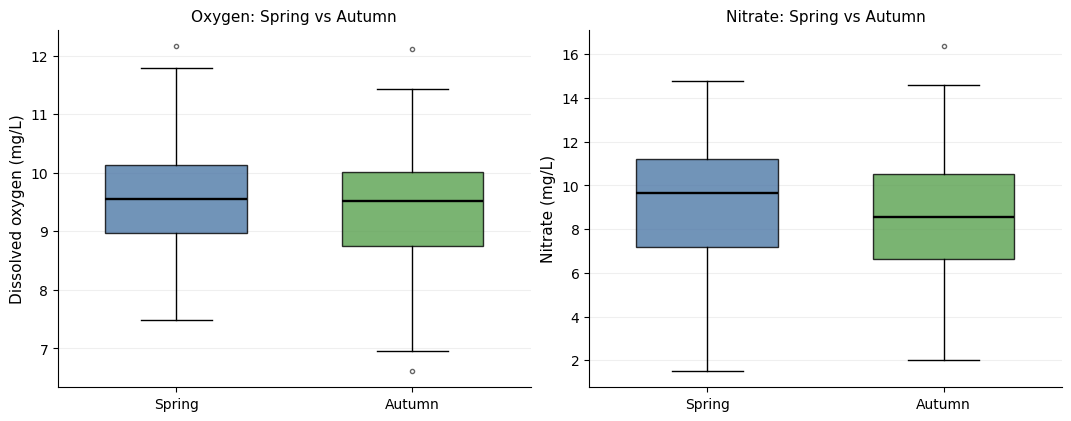

In [32]:

fig, axes = plt.subplots(
    1, 2, figsize=(10.6, 4.1),
    constrained_layout=True
)

for ax, (column, ylabel, title) in zip(axes, variables):
    draw_boxplot(
        ax,
        group_col="saison",
        variable=column,
        order=["spring", "autumn"],
        labels=["Spring", "Autumn"],
        colors=["#4E79A7", "#59A14F"]
    )

    ax.set_title(f"{title}: Spring vs Autumn")
    ax.set_ylabel(ylabel)

fig.savefig(
    output_dir / "Figure_1_Spring_Autumn_Boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


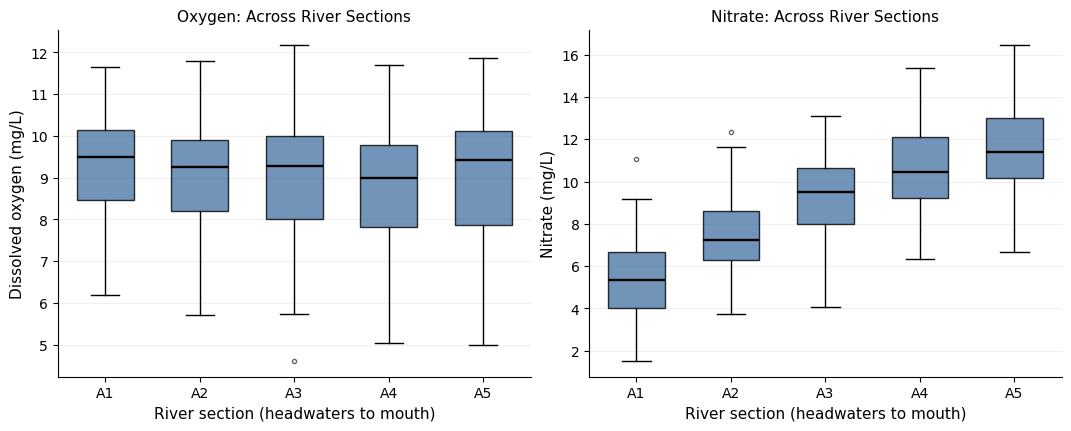

In [33]:

fig, axes = plt.subplots(
    1, 2, figsize=(10.6, 4.2),
    constrained_layout=True
)

for ax, (column, ylabel, title) in zip(axes, variables):
    draw_boxplot(
        ax,
        group_col="river_section",
        variable=column,
        order=section_order,
        labels=["A1", "A2", "A3", "A4", "A5"],
        colors=["#4E79A7"] * 5
    )

    ax.set_title(f"{title}: Across River Sections")
    ax.set_xlabel("River section (headwaters to mouth)")
    ax.set_ylabel(ylabel)

fig.savefig(
    output_dir / "Figure_2_River_Section_Boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


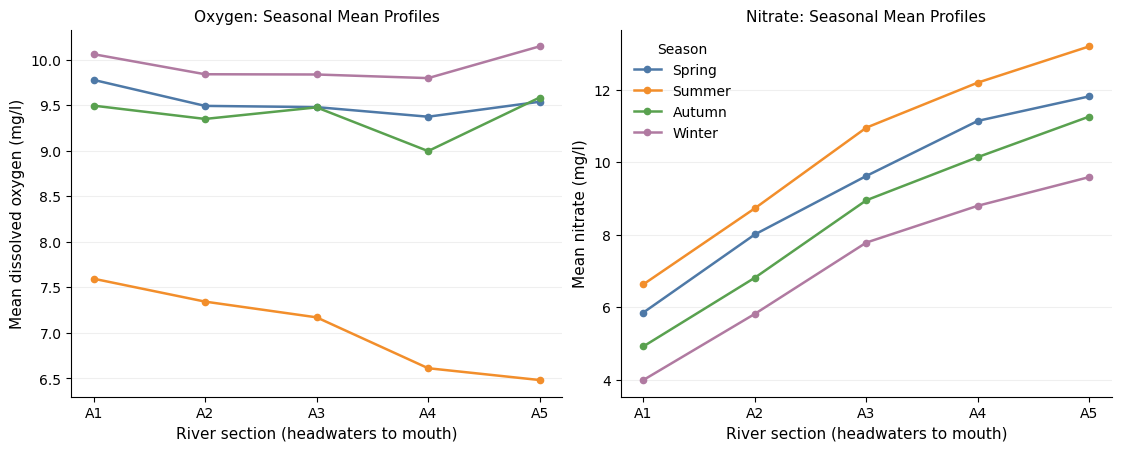

In [34]:

season_colors = {
    "spring": "#4E79A7",
    "summer": "#F28E2B",
    "autumn": "#59A14F",
    "winter": "#B07AA1"
}

fig, axes = plt.subplots(
    1, 2, figsize=(11.1, 4.4),
    constrained_layout=True
)

for ax, (column, ylabel, title) in zip(axes, variables):

    means = df.pivot_table(
        index="river_section",
        columns="saison",
        values=column,
        aggfunc="mean"
    ).reindex(index=section_order, columns=season_order)

    for season in season_order:
        ax.plot(
            range(5),
            means[season],
            marker="o",
            markersize=4.5,
            linewidth=1.8,
            color=season_colors[season],
            label=season.capitalize()
        )

    ax.set_xticks(range(5))
    ax.set_xticklabels(["A1", "A2", "A3", "A4", "A5"])
    ax.set_xlabel("River section (headwaters to mouth)")
    ax.set_ylabel("Mean " + ylabel.lower())
    ax.set_title(f"{title}: Seasonal Mean Profiles")
    ax.grid(axis="y", alpha=0.2)

axes[1].legend(title="Season", frameon=False)

fig.savefig(
    output_dir / "Figure_3_Season_by_Section_Mean_Profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [35]:

from scipy.stats import shapiro, levene
import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

measurements = ["oxygen_mgL", "nitrate_mgL"]

models = {}
diagnostic_results = []

for variable in measurements:

    # Fit a two-way model including interaction
    model = smf.ols(
        f"{variable} ~ C(saison) * C(river_section)",
        data=df
    ).fit()

    models[variable] = model

    # Model residuals
    residuals = model.resid

    # Shapiro-Wilk normality test
    shapiro_stat, shapiro_p = shapiro(residuals)

    # Concentration measurements in the 20 groups
    groups = [
        group[variable].to_numpy()
        for _, group in df.groupby(
            ["river_section", "saison"]
        )
    ]

    # Median-centered Levene / Brown-Forsythe test
    levene_stat, levene_p = levene(
        *groups, center="median"
    )

    diagnostic_results.append({
        "Variable": variable,
        "Shapiro W": shapiro_stat,
        "Shapiro p": shapiro_p,
        "Levene F": levene_stat,
        "Levene p": levene_p
    })

diagnostics = pd.DataFrame(diagnostic_results)

display(diagnostics.round(4))


,Variable,Shapiro W,Shapiro p,Levene F,Levene p
0,oxygen_mgL,0.9991,0.9433,1.0103,0.4459
1,nitrate_mgL,0.9989,0.8499,0.7201,0.8005


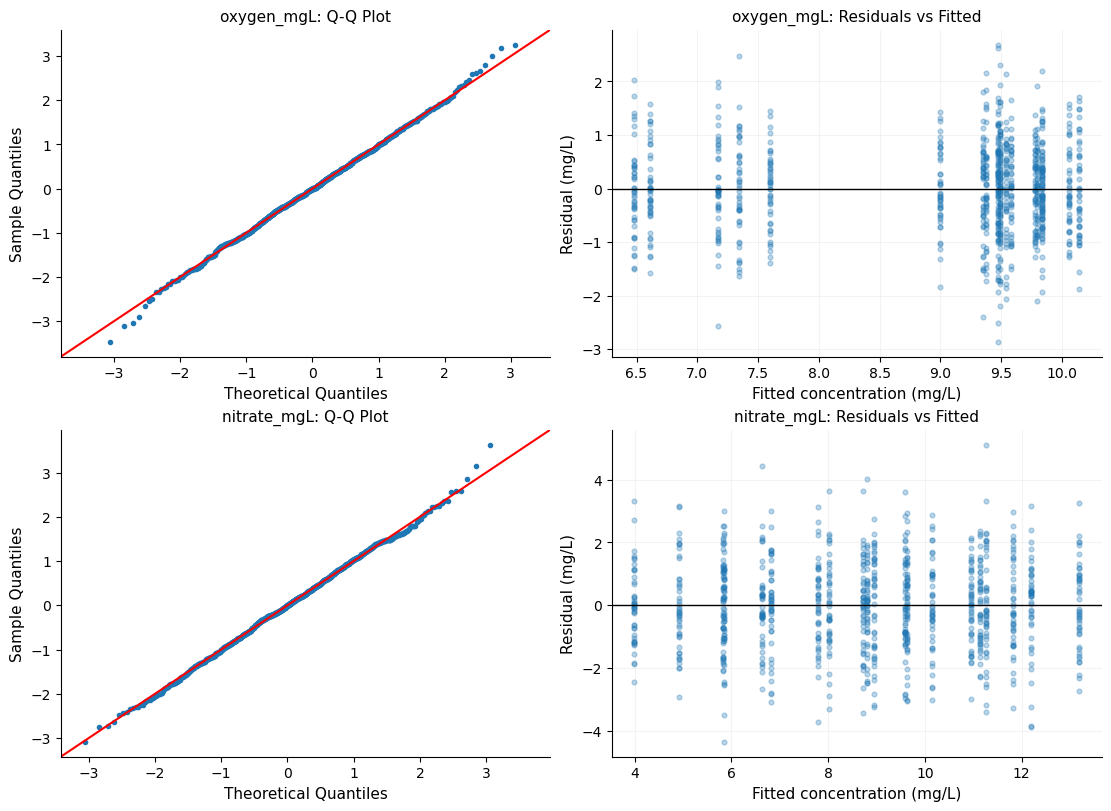

In [36]:

import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

output_dir = Path("results/step_4")
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 8),
    constrained_layout=True
)

for i, variable in enumerate(measurements):

    model = models[variable]
    residuals = model.resid

    # Standardize residuals for the Q-Q plot
    z = (
        (residuals - residuals.mean())
        / residuals.std(ddof=1)
    )

    # Q-Q plot
    sm.qqplot(
        z,
        line="45",
        ax=axes[i, 0],
        markersize=3
    )

    axes[i, 0].set_title(
        f"{variable}: Q-Q Plot"
    )

    # Residuals against fitted values
    axes[i, 1].scatter(
        model.fittedvalues,
        residuals,
        alpha=0.3,
        s=12
    )

    axes[i, 1].axhline(
        y=0,
        color="black",
        linewidth=1
    )

    axes[i, 1].set_title(
        f"{variable}: Residuals vs Fitted"
    )

    axes[i, 1].set_xlabel(
        "Fitted concentration (mg/L)"
    )

    axes[i, 1].set_ylabel(
        "Residual (mg/L)"
    )

    axes[i, 1].grid(alpha=0.15)

fig.savefig(
    output_dir / "residual_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [37]:

outlier_results = []

for variable in measurements:

    total_outliers = 0

    for _, group in df.groupby(
        ["river_section", "saison"]
    ):

        values = group[variable]

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = (
            (values < lower) |
            (values > upper)
        ).sum()

        total_outliers += int(count)

    outlier_results.append({
        "Variable": variable,
        "Potential outliers": total_outliers,
        "Total observations": len(df),
        "Percentage": round(
            total_outliers / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)


,Variable,Potential outliers,Total observations,Percentage
0,oxygen_mgL,13,900,1.44
1,nitrate_mgL,14,900,1.56


In [38]:

import numpy as np
import pandas as pd
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

measurements = ["oxygen_mgL", "nitrate_mgL"]
section_order = sorted(df["river_section"].unique())

# Verify the balanced study design
counts = df.groupby(["river_section", "saison"]).size()
assert (counts == 45).all(), "Unexpected group sizes"

results = []

for variable in measurements:

    # Full factorial model
    model = smf.ols(
        f"{variable} ~ C(saison) * C(river_section)",
        data=df
    ).fit()

    # Calculate season-section means
    means = df.groupby(
        ["saison", "river_section"]
    )[variable].mean()

    spring = means.loc["spring"].reindex(section_order)
    autumn = means.loc["autumn"].reindex(section_order)

    # Average spring-autumn contrast across sections
    difference = (spring - autumn).mean()

    # Standard error based on the full factorial model
    se = np.sqrt(2 * model.mse_resid / 225)

    # Two-sided t-test
    t_stat = difference / se
    df_resid = model.df_resid

    p_value = 2 * student_t.sf(
        abs(t_stat), df=df_resid
    )

    # Individual 95% confidence interval
    critical_t = student_t.ppf(0.975, df_resid)

    ci_lower = difference - critical_t * se
    ci_upper = difference + critical_t * se

    # Model-based standardized mean difference
    effect_size = difference / np.sqrt(model.mse_resid)

    results.append({
        "Variable": variable,
        "Spring mean": spring.mean(),
        "Autumn mean": autumn.mean(),
        "Mean difference": difference,
        "SE": se,
        "t-statistic": t_stat,
        "df": int(df_resid),
        "p-value": p_value,
        "CI lower": ci_lower,
        "CI upper": ci_upper,
        "Standardized difference": effect_size
    })

results_df = pd.DataFrame(results)

# Holm correction across the two outcome tests
results_df["Holm p-value"] = multipletests(
    results_df["p-value"],
    method="holm"
)[1]

display(results_df.style.format(precision=6))


,Variable,Spring mean,Autumn mean,Mean difference,SE,t-statistic,df,p-value,CI lower,CI upper,Standardized difference,Holm p-value
0,oxygen_mgL,9.530813,9.378876,0.151938,0.078597,1.933125,880,0.053541,-0.002322,0.306197,0.182257,0.053541
1,nitrate_mgL,9.288844,8.418182,0.870662,0.134239,6.485895,880,0.000000,0.607196,1.134129,0.611496,0.000000


In [39]:

section_differences = df.pivot_table(
    index="river_section",
    columns="saison",
    values=measurements,
    aggfunc="mean"
)

for variable in measurements:
    section_differences[(variable, "difference")] = (
        section_differences[(variable, "spring")]
        - section_differences[(variable, "autumn")]
    )

difference_table = pd.DataFrame({
    "Oxygen difference (mg/L)":
        section_differences[
            ("oxygen_mgL", "difference")
        ],
    "Nitrate difference (mg/L)":
        section_differences[
            ("nitrate_mgL", "difference")
        ]
})

display(difference_table.round(4))


,Oxygen difference (mg/L),Nitrate difference (mg/L)
river_section,,
A1_headwaters,0.2826,0.9336
A2_upper_course,0.1432,1.1932
A3_middle_course,0.0028,0.6704
A4_lower_course,0.3773,0.9994
A5_mouth,-0.0462,0.5568


In [40]:

from pathlib import Path

output_dir = Path("results/step_5")
output_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    output_dir / "spring_autumn_hypothesis_tests.csv",
    index=False
)

difference_table.to_csv(
    output_dir / "spring_autumn_section_differences.csv"
)

print("Step 5 results saved successfully.")


Step 5 results saved successfully.


In [41]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols

outcomes = {
    "oxygen_mgL": "Oxygen",
    "nitrate_mgL": "Nitrate"
}

effects = {
    "C(saison, Sum)": "Season",
    "C(river_section, Sum)": "River section",
    "C(saison, Sum):C(river_section, Sum)": "Interaction"
}

models_step6 = {}
anova_tables = {}
anova_results = []

for variable, label in outcomes.items():

    # Fit two-way factorial ANOVA
    model = ols(
        f"{variable} ~ C(saison, Sum) * C(river_section, Sum)",
        data=df
    ).fit()

    models_step6[variable] = model

    # Type III ANOVA
    anova = sm.stats.anova_lm(model, typ=3)
    anova = anova.drop(index="Intercept")

    anova_tables[variable] = anova

    # Residual sum of squares
    ss_error = anova.loc["Residual", "sum_sq"]
    df_error = int(anova.loc["Residual", "df"])

    for term, effect_name in effects.items():

        ss_effect = anova.loc[term, "sum_sq"]

        # Partial eta-squared
        eta_partial = ss_effect / (ss_effect + ss_error)

        anova_results.append({
            "Outcome": label,
            "Effect": effect_name,
            "df1": int(anova.loc[term, "df"]),
            "df2": df_error,
            "F": anova.loc[term, "F"],
            "p": anova.loc[term, "PR(>F)"],
            "Partial eta²": eta_partial
        })

anova_summary = pd.DataFrame(anova_results)

display(
    anova_summary.style.format({
        "F": "{:.3f}",
        "p": "{:.3e}",
        "Partial eta²": "{:.4f}"
    })
)


,Outcome,Effect,df1,df2,F,p,Partial eta²
0,Oxygen,Season,3,880,554.258,3.308e-202,0.6539
1,Oxygen,River section,4,880,9.519,1.548e-07,0.0415
2,Oxygen,Interaction,12,880,3.897,7.457e-06,0.0505
3,Nitrate,Season,3,880,197.138,8.837e-98,0.4019
4,Nitrate,River section,4,880,544.834,2.477e-236,0.7124
5,Nitrate,Interaction,12,880,0.856,5.928e-01,0.0115


In [42]:

from statsmodels.stats.multitest import multipletests

anova_summary["Holm p"] = np.nan

for effect in ["River section", "Interaction"]:

    mask = anova_summary["Effect"] == effect

    adjusted = multipletests(
        anova_summary.loc[mask, "p"],
        method="holm"
    )[1]

    anova_summary.loc[mask, "Holm p"] = adjusted

anova_summary["Significant (raw)"] = (
    anova_summary["p"] < 0.05
)

display(
    anova_summary.style.format({
        "F": "{:.3f}",
        "p": "{:.3e}",
        "Partial eta²": "{:.4f}",
        "Holm p": "{:.3e}",
        "Significant (raw)": "{}"
    })
)


,Outcome,Effect,df1,df2,F,p,Partial eta²,Holm p,Significant (raw)
0,Oxygen,Season,3,880,554.258,3.308e-202,0.6539,nan,True
1,Oxygen,River section,4,880,9.519,1.548e-07,0.0415,1.548e-07,True
2,Oxygen,Interaction,12,880,3.897,7.457e-06,0.0505,1.491e-05,True
3,Nitrate,Season,3,880,197.138,8.837e-98,0.4019,nan,True
4,Nitrate,River section,4,880,544.834,2.477e-236,0.7124,4.954e-236,True
5,Nitrate,Interaction,12,880,0.856,5.928e-01,0.0115,5.928e-01,False


In [43]:

section_order = [
    "A1_headwaters",
    "A2_upper_course",
    "A3_middle_course",
    "A4_lower_course",
    "A5_mouth"
]

section_means = (
    df.groupby("river_section")[
        ["oxygen_mgL", "nitrate_mgL"]
    ]
    .mean()
    .reindex(section_order)
)

display(section_means.round(3))


,oxygen_mgL,nitrate_mgL
river_section,,
A1_headwaters,9.231,5.350
A2_upper_course,9.005,7.343
A3_middle_course,8.990,9.328
A4_lower_course,8.694,10.570
A5_mouth,8.936,11.467


In [44]:

from pathlib import Path

output_dir = Path("results/step_6")
output_dir.mkdir(parents=True, exist_ok=True)

anova_summary.to_csv(
    output_dir / "two_way_anova_summary.csv",
    index=False
)

section_means.to_csv(
    output_dir / "river_section_means.csv"
)

for variable, table in anova_tables.items():
    table.to_csv(
        output_dir / f"{variable}_anova.csv"
    )

print("Step 6 results saved successfully.")


Step 6 results saved successfully.


In [45]:

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

from itertools import combinations
from scipy.stats import t, studentized_range
from statsmodels.stats.multitest import multipletests

seasons = ["spring", "summer", "autumn", "winter"]
sections = sorted(df["river_section"].unique())

# Verify expected group sizes
counts = df.groupby(["saison", "river_section"]).size()
assert counts.eq(45).all() and len(counts) == 20

# Full factorial oxygen model
oxygen_model = smf.ols(
    "oxygen_mgL ~ C(saison, Sum) * C(river_section, Sum)",
    data=df
).fit()

oxygen_means = df.groupby(
    ["saison", "river_section"]
)["oxygen_mgL"].mean()

# Standard error of a within-season section difference
oxygen_se = np.sqrt(
    2 * oxygen_model.mse_resid / 45
)

rows = []

for season in seasons:
    for first, second in combinations(sections, 2):

        difference = (
            oxygen_means[season, first]
            - oxygen_means[season, second]
        )

        t_stat = difference / oxygen_se

        p_value = 2 * t.sf(
            abs(t_stat),
            df=oxygen_model.df_resid
        )

        rows.append({
            "Season": season,
            "Pair": f"{first[:2]} - {second[:2]}",
            "Difference": difference,
            "t": t_stat,
            "Raw p": p_value
        })

oxygen_posthoc = pd.DataFrame(rows)

# Holm correction across all 40 comparisons
oxygen_posthoc["Holm p"] = multipletests(
    oxygen_posthoc["Raw p"],
    method="holm"
)[1]

oxygen_posthoc["Significant"] = (
    oxygen_posthoc["Holm p"] < 0.05
)

# Conservative simultaneous 95% confidence intervals
critical = t.ppf(
    1 - 0.05 / (2 * len(oxygen_posthoc)),
    oxygen_model.df_resid
)

oxygen_posthoc["CI lower"] = (
    oxygen_posthoc["Difference"] - critical * oxygen_se
)

oxygen_posthoc["CI upper"] = (
    oxygen_posthoc["Difference"] + critical * oxygen_se
)

print("Significant oxygen comparisons by season:")
display(
    oxygen_posthoc.groupby("Season")["Significant"].sum()
)

print("Significant pairwise comparisons:")
display(
    oxygen_posthoc.loc[
        oxygen_posthoc["Significant"]
    ].round(5)
)


Significant oxygen comparisons by season:


Season
autumn    1
spring    0
summer    5
winter    0
Name: Significant, dtype: int64

Significant pairwise comparisons:


,Season,Pair,Difference,t,Raw p,Holm p,Significant,CI lower,CI upper
12,summer,A1 - A4,0.98233,5.58944,0.00000,0.00000,True,0.41331,1.55136
13,summer,A1 - A5,1.11220,6.32837,0.00000,0.00000,True,0.54318,1.68122
15,summer,A2 - A4,0.73084,4.15848,0.00004,0.00130,True,0.16182,1.29987
16,summer,A2 - A5,0.86071,4.89741,0.00000,0.00004,True,0.29169,1.42973
18,summer,A3 - A5,0.68809,3.91520,0.00010,0.00350,True,0.11907,1.25711
29,autumn,A4 - A5,-0.58764,-3.34367,0.00086,0.03016,True,-1.15667,-0.01862


In [46]:

# Full factorial nitrate model
nitrate_model = smf.ols(
    "nitrate_mgL ~ C(saison, Sum) * C(river_section, Sum)",
    data=df
).fit()

# Means averaged over the four seasons
nitrate_means = df.groupby(
    "river_section"
)["nitrate_mgL"].mean()

n_per_section = 180
n_sections = len(sections)

# Standard error used for Tukey's q statistic
q_se = np.sqrt(
    nitrate_model.mse_resid / n_per_section
)

q_critical = studentized_range.ppf(
    0.95,
    n_sections,
    nitrate_model.df_resid
)

rows = []

for first, second in combinations(sections, 2):

    difference = (
        nitrate_means[first] - nitrate_means[second]
    )

    q_stat = abs(difference) / q_se

    p_adjusted = studentized_range.sf(
        q_stat,
        n_sections,
        nitrate_model.df_resid
    )

    margin = q_critical * q_se

    rows.append({
        "Pair": f"{first[:2]} - {second[:2]}",
        "Difference": difference,
        "Tukey p": p_adjusted,
        "CI lower": difference - margin,
        "CI upper": difference + margin,
        "Significant": p_adjusted < 0.05
    })

nitrate_posthoc = pd.DataFrame(rows)

print("Nitrate Tukey pairwise comparisons:")
display(nitrate_posthoc.round(5))

print(
    "Significant pairs:",
    nitrate_posthoc["Significant"].sum(),
    "out of",
    len(nitrate_posthoc)
)


Nitrate Tukey pairwise comparisons:


,Pair,Difference,Tukey p,CI lower,CI upper,Significant
0,A1 - A2,-1.99254,0.0,-2.40279,-1.58229,True
1,A1 - A3,-3.97802,0.0,-4.38826,-3.56777,True
2,A1 - A4,-5.21965,0.0,-5.62990,-4.80940,True
3,A1 - A5,-6.11618,0.0,-6.52643,-5.70594,True
4,A2 - A3,-1.98548,0.0,-2.39572,-1.57523,True
5,A2 - A4,-3.22711,0.0,-3.63736,-2.81686,True
6,A2 - A5,-4.12364,0.0,-4.53389,-3.71340,True
7,A3 - A4,-1.24163,0.0,-1.65188,-0.83139,True
8,A3 - A5,-2.13817,0.0,-2.54841,-1.72792,True
9,A4 - A5,-0.89653,0.0,-1.30678,-0.48629,True


Significant pairs: 10 out of 10


In [47]:

from pathlib import Path

output_dir = Path("results/step_7")
output_dir.mkdir(parents=True, exist_ok=True)

oxygen_posthoc.to_csv(
    output_dir / "oxygen_all_40_comparisons.csv",
    index=False
)

nitrate_posthoc.to_csv(
    output_dir / "nitrate_all_10_comparisons.csv",
    index=False
)

oxygen_posthoc.loc[
    oxygen_posthoc["Significant"]
].to_csv(
    output_dir / "oxygen_significant_pairs.csv",
    index=False
)

print("Step 7 results exported successfully.")


Step 7 results exported successfully.


In [48]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from patsy import build_design_matrices
from statsmodels.stats.multitest import multipletests

df = pd.read_csv(
    "waterquality.csv",
    sep=";",
    decimal="."
)

outcomes = ["oxygen_mgL", "nitrate_mgL"]
sections = sorted(df["river_section"].unique())

def spring_autumn_contrast(model):
    # Equal-weight average across the five river sections
    new_data = pd.DataFrame({
        "saison": (
            ["spring"] * len(sections)
            + ["autumn"] * len(sections)
        ),
        "river_section": sections + sections
    })

    X = np.asarray(build_design_matrices(
        [model.model.data.design_info],
        new_data
    )[0])

    n = len(sections)
    return X[:n].mean(axis=0) - X[n:].mean(axis=0)

models8 = {}
robust_models8 = {}
primary_results = []

for variable in outcomes:

    model = smf.ols(
        f"{variable} ~ C(saison, Sum) * C(river_section, Sum)",
        data=df
    ).fit()

    robust = model.get_robustcov_results(cov_type="HC3")

    models8[variable] = model
    robust_models8[variable] = robust

    contrast = spring_autumn_contrast(model)

    standard_test = model.t_test(contrast)
    robust_test = robust.t_test(contrast)

    difference = standard_test.effect.item()

    primary_results.append({
        "Variable": variable,
        "Mean difference": difference,
        "Standardized d": difference / np.sqrt(model.mse_resid),
        "Original p": standard_test.pvalue.item(),
        "HC3 p": robust_test.pvalue.item(),
        "HC3 CI lower": robust_test.conf_int()[0, 0],
        "HC3 CI upper": robust_test.conf_int()[0, 1]
    })

primary_df = pd.DataFrame(primary_results)

primary_df["HC3 Holm p"] = multipletests(
    primary_df["HC3 p"],
    method="holm"
)[1]

display(primary_df)


,Variable,Mean difference,Standardized d,Original p,HC3 p,HC3 CI lower,HC3 CI upper,HC3 Holm p
0,oxygen_mgL,0.151938,0.182257,5.354131e-02,6.505724e-02,-0.009499,0.313375,6.505724e-02
1,nitrate_mgL,0.870662,0.611496,1.469446e-10,1.227659e-09,0.592474,1.148850,2.455319e-09


In [49]:

sensitivity_results = []

for variable in outcomes:

    # Identify potential outliers within each season-section cell
    flagged = pd.Series(False, index=df.index)

    for _, group in df.groupby(
        ["saison", "river_section"]
    ):

        q1 = group[variable].quantile(0.25)
        q3 = group[variable].quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        flagged.loc[group.index] = (
            (group[variable] < lower)
            | (group[variable] > upper)
        )

    # Sensitivity analysis only: retain original df
    sensitivity_df = df.loc[~flagged].copy()

    model = smf.ols(
        f"{variable} ~ C(saison, Sum) * C(river_section, Sum)",
        data=sensitivity_df
    ).fit()

    contrast = spring_autumn_contrast(model)
    test = model.t_test(contrast)

    anova = sm.stats.anova_lm(model, typ=3)

    sensitivity_results.append({
        "Variable": variable,
        "Flagged observations": int(flagged.sum()),
        "Retained observations": len(sensitivity_df),
        "Mean difference": test.effect.item(),
        "p-value": test.pvalue.item(),
        "Section p-value": anova.loc[
            "C(river_section, Sum)", "PR(>F)"
        ],
        "Interaction p-value": anova.loc[
            "C(saison, Sum):C(river_section, Sum)",
            "PR(>F)"
        ]
    })

sensitivity_table = pd.DataFrame(sensitivity_results)

display(sensitivity_table)


,Variable,Flagged observations,Retained observations,Mean difference,p-value,Section p-value,Interaction p-value
0,oxygen_mgL,13,887,0.104994,1.625283e-01,2.542599e-08,1.880969e-07
1,nitrate_mgL,14,886,0.913665,2.180218e-12,1.627355e-245,2.835721e-01


In [50]:

effects = {
    "C(river_section, Sum)": "River section",
    "C(saison, Sum):C(river_section, Sum)": "Interaction"
}

robust_anova_results = []

for variable in outcomes:

    model = models8[variable]
    robust = robust_models8[variable]

    conventional = sm.stats.anova_lm(model, typ=3)

    robust_tests = robust.wald_test_terms(
        skip_single=False
    ).table

    for term, label in effects.items():

        robust_anova_results.append({
            "Variable": variable,
            "Effect": label,
            "Original p": conventional.loc[
                term, "PR(>F)"
            ],
            "HC3 p": float(
                np.asarray(
                    robust_tests.loc[term, "pvalue"]
                ).ravel()[0]
            )
        })

robust_anova_df = pd.DataFrame(robust_anova_results)

display(robust_anova_df)


d:\Masrafe\Coding\python\anaconda\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
d:\Masrafe\Coding\python\anaconda\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


,Variable,Effect,Original p,HC3 p
0,oxygen_mgL,River section,1.548348e-07,1.882971e-08
1,oxygen_mgL,Interaction,7.457119e-06,4.161565e-06
2,nitrate_mgL,River section,2.476802e-236,4.261632e-232
3,nitrate_mgL,Interaction,5.927639e-01,5.700565e-01


In [51]:

from itertools import combinations

seasons = ["spring", "summer", "autumn", "winter"]

robust_pairwise_tables = {}

for variable in outcomes:

    model = models8[variable]
    robust = robust_models8[variable]

    rows = []

    if variable == "oxygen_mgL":
        comparison_groups = [
            (season, a, b)
            for season in seasons
            for a, b in combinations(sections, 2)
        ]
    else:
        comparison_groups = [
            (None, a, b)
            for a, b in combinations(sections, 2)
        ]

    for season, a, b in comparison_groups:

        if season is not None:
            # Compare two sections within the same season
            new_data = pd.DataFrame({
                "saison": [season, season],
                "river_section": [a, b]
            })
        else:
            # Compare sections averaged over all seasons
            new_data = pd.DataFrame({
                "saison": seasons + seasons,
                "river_section": [a] * 4 + [b] * 4
            })

        X = np.asarray(build_design_matrices(
            [model.model.data.design_info],
            new_data
        )[0])

        if season is not None:
            contrast = X[0] - X[1]
        else:
            contrast = X[:4].mean(axis=0) - X[4:].mean(axis=0)

        test = robust.t_test(contrast)

        rows.append({
            "Season": season if season else "Overall",
            "Pair": f"{a[:2]} - {b[:2]}",
            "Difference": test.effect.item(),
            "HC3 p": test.pvalue.item()
        })

    table = pd.DataFrame(rows)

    table["Holm p"] = multipletests(
        table["HC3 p"],
        method="holm"
    )[1]

    table["Significant"] = table["Holm p"] < 0.05

    robust_pairwise_tables[variable] = table

    print(f"\n{variable}")
    print(
        "Significant:",
        table["Significant"].sum(),
        "of",
        len(table)
    )

    display(table.loc[table["Significant"]])



oxygen_mgL
Significant: 6 of 40


,Season,Pair,Difference,HC3 p,Holm p,Significant
12,summer,A1 - A4,0.982333,8.180355e-10,3.190338e-08,True
13,summer,A1 - A5,1.112200,2.299280e-11,9.197122e-10,True
15,summer,A2 - A4,0.730844,6.181994e-05,2.287338e-03,True
16,summer,A2 - A5,0.860711,4.684840e-06,1.780239e-04,True
18,summer,A3 - A5,0.688089,2.252707e-04,8.109746e-03,True
29,autumn,A4 - A5,-0.587644,2.297260e-04,8.109746e-03,True



nitrate_mgL
Significant: 10 of 10


,Season,Pair,Difference,HC3 p,Holm p,Significant
0,Overall,A1 - A2,-1.992539,6.110461e-37,2.444184e-36,True
1,Overall,A1 - A3,-3.978017,1.487105e-114,1.189684e-113,True
2,Overall,A1 - A4,-5.219650,3.322779e-170,2.990502e-169,True
3,Overall,A1 - A5,-6.116183,7.939397e-196,7.939397e-195,True
4,Overall,A2 - A3,-1.985478,1.582490e-36,4.747470e-36,True
5,Overall,A2 - A4,-3.227111,4.347320e-84,2.608392e-83,True
6,Overall,A2 - A5,-4.123644,8.200109e-114,5.740076e-113,True
7,Overall,A3 - A4,-1.241633,2.591535e-16,5.183071e-16,True
8,Overall,A3 - A5,-2.138167,7.250355e-39,3.625177e-38,True
9,Overall,A4 - A5,-0.896533,9.150036e-09,9.150036e-09,True


In [52]:

from pathlib import Path

output_dir = Path("results/step_8")
output_dir.mkdir(parents=True, exist_ok=True)

primary_df.to_csv(
    output_dir / "primary_effects_robustness.csv",
    index=False
)

sensitivity_table.to_csv(
    output_dir / "outlier_sensitivity.csv",
    index=False
)

robust_anova_df.to_csv(
    output_dir / "robust_anova_verification.csv",
    index=False
)

for variable, table in robust_pairwise_tables.items():
    table.to_csv(
        output_dir / f"{variable}_robust_pairwise.csv",
        index=False
    )

print("Step 8 results saved successfully.")


Step 8 results saved successfully.


In [53]:
%run step9_finalize_results.py --csv waterquality.csv --out results/step_9

Step 9 complete — all main numerical checks passed.
Spring–autumn contrasts:
    variable  mean_diff_mgL       p_holm
 oxygen_mgL       0.151938 5.354131e-02
nitrate_mgL       0.870662 2.938891e-10
Significant pairs: oxygen 6 / 40; nitrate 10 / 10
Results saved to: D:\Masrafe\Coding\Git_Hub_code\python\TUD\summer2027\results\step_9


In [54]:
import pandas as pd

# Spring vs autumn results
display(pd.read_csv(
    "results/step_9/report_table_2_spring_autumn.csv"
))

# Two-way ANOVA results
display(pd.read_csv(
    "results/step_9/report_table_3_anova.csv"
))

# Significant oxygen comparisons
display(pd.read_csv(
    "results/step_9/report_table_4_oxygen_significant_pairs.csv"
))

# Nitrate pairwise comparisons
display(pd.read_csv(
    "results/step_9/report_table_5_nitrate_all_pairs.csv"
))

,variable,spring_mean,autumn_mean,mean_diff_mgL,t,df,p,ci_lower_mgL,ci_upper_mgL,pooled_residual_standardized_d,hc3_p,hc3_ci_lower_mgL,hc3_ci_upper_mgL,p_holm,hc3_p_holm
0,oxygen_mgL,9.530813,9.378876,0.151938,1.933125,880,5.354131e-02,-0.002322,0.306197,0.182257,6.505724e-02,-0.009499,0.313375,5.354131e-02,6.505724e-02
1,nitrate_mgL,9.288844,8.418182,0.870662,6.485895,880,1.469446e-10,0.607196,1.134129,0.611496,1.227659e-09,0.592474,1.148850,2.938891e-10,2.455319e-09


,variable,effect,df1,df2,F,p,partial_eta_squared,holm_p
0,oxygen_mgL,Season,3,880,554.258050,3.307680e-202,0.653921,NaN
1,oxygen_mgL,River section,4,880,9.519383,1.548348e-07,0.041475,1.548348e-07
2,oxygen_mgL,Interaction,12,880,3.896729,7.457119e-06,0.050456,1.491424e-05
3,nitrate_mgL,Season,3,880,197.138206,8.837051e-98,0.401936,NaN
4,nitrate_mgL,River section,4,880,544.834238,2.476802e-236,0.712356,4.953605e-236
5,nitrate_mgL,Interaction,12,880,0.855509,5.927639e-01,0.011532,5.927639e-01


,season,pair,difference_mgL,t,p_raw,p_holm,significant
0,summer,A1 - A4,0.982333,5.589437,3.038734e-08,1.185106e-06,True
1,summer,A1 - A5,1.112200,6.328373,3.941574e-10,1.576629e-08,True
2,summer,A2 - A4,0.730844,4.158475,3.517432e-05,1.301450e-03,True
3,summer,A2 - A5,0.860711,4.897411,1.155343e-06,4.390304e-05,True
4,summer,A3 - A5,0.688089,3.915198,9.731069e-05,3.503185e-03,True
5,autumn,A4 - A5,-0.587644,-3.343673,8.616861e-04,3.015901e-02,True


,pair,difference_mgL,p_tukey,ci_lower_mgL,ci_upper_mgL,significant
0,A1 - A2,-1.992539,2.275957e-14,-2.402785,-1.582293,True
1,A1 - A3,-3.978017,2.275957e-14,-4.388263,-3.567770,True
2,A1 - A4,-5.219650,2.275957e-14,-5.629896,-4.809404,True
3,A1 - A5,-6.116183,2.275957e-14,-6.526430,-5.705937,True
4,A2 - A3,-1.985478,2.275957e-14,-2.395724,-1.575232,True
5,A2 - A4,-3.227111,2.275957e-14,-3.637357,-2.816865,True
6,A2 - A5,-4.123644,2.275957e-14,-4.533891,-3.713398,True
7,A3 - A4,-1.241633,2.742251e-14,-1.651880,-0.831387,True
8,A3 - A5,-2.138167,2.275957e-14,-2.548413,-1.727920,True
9,A4 - A5,-0.896533,3.361799e-08,-1.306780,-0.486287,True
